## Verificar os dados

In [1]:
%pip install -r requirements.txt

from pathlib import Path

# Este notebook usa o ficheiro limpo que o 01_EDA grava no fim
LIMPO = Path("data/kingcounty/kc_clean.csv")
if not LIMPO.exists():
    raise FileNotFoundError(f"{LIMPO} não existe. Executa primeiro o notebook 01_EDA.")


print("Dataset limpo em:", LIMPO)


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Dataset limpo em: data/kingcounty/kc_clean.csv


## Objetivo

Queremos saber se uma casa vendida no condado de King ficou abaixo, perto ou acima do preço esperado para o seu tamanho e localização, e que características explicam essa diferença. O preço esperado só tem em conta o tamanho, a zona e o mês da venda, por isso uma venda acima do esperado pode ter um preço justificado, por exemplo pela vista ou pela qualidade da construção. Isto ajuda agências e avaliadores a saber o que pesa no preço além da área e da zona.

Usa o `kc_clean.csv` gerado pelo `01_EDA`.

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

from libs.decisiontrees import DecisionTreeClassifier

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 250)

SEMENTE = 42
CLASSES = ["baixo", "normal", "alto"]

O preço esperado de cada venda foi estimado com uma regressão sobre o log do preço, com `AreaCasa`, `AreaTerreno`, `bedrooms`, `bathrooms`, o código postal e o mês da venda. Mais de 12% abaixo do esperado é `baixo`, mais de 12% acima é `alto` e o resto é `normal`.

## Preparar os dados

Todas as vendas têm classe.

In [3]:
dados = pd.read_csv("data/kingcounty/kc_clean.csv", parse_dates=["date"])

vendas = dados[dados["ClassePreco"].notna()].reset_index(drop=True)
print(f"{len(vendas)} vendas com classe (de {len(dados)} linhas)")
vendas["ClassePreco"].value_counts(normalize=True).round(3)

21613 vendas com classe (de 21613 linhas)


ClassePreco
normal    0.529
alto      0.247
baixo     0.224
Name: proportion, dtype: float64

Além das variáveis da regressão entram `floors`, `waterfront`, `view`, `condition`, `grade`, `AreaCave`, `yr_built`, `AreaCasaVizinhos`, `AreaTerrenoVizinhos` e os `Meses` desde a primeira venda. Do `01_EDA` vêm também `Renovada`, que é 1 quando a casa foi renovada, e `AnoUltimaObra`, o ano da renovação ou o da construção se a casa nunca foi renovada.

Removemos `price`, `PrecoEsperado` e `DesvioPreco`, porque definem a classe, e o código postal e as coordenadas, porque a localização já está no preço esperado. Também removemos `AreaAcimaChao`, que é a área da casa menos a da cave.

In [4]:
vendas["Meses"] = (vendas["date"] - vendas["date"].min()).dt.days / 30.44

NUMERICAS = ["bedrooms", "bathrooms", "AreaCasa", "AreaTerreno", "floors", "waterfront", "view", "condition", "grade",
             "AreaCave", "yr_built", "AreaCasaVizinhos", "AreaTerrenoVizinhos", "Meses", "Renovada", "AnoUltimaObra"]
ALVO = "ClassePreco"

vendas[NUMERICAS].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
bedrooms,21613.0,3.4,0.9,0.0,3.0,3.0,4.0,11.0
bathrooms,21613.0,2.1,0.8,0.0,1.8,2.2,2.5,8.0
AreaCasa,21613.0,193.2,85.3,26.9,132.6,177.4,236.9,1257.9
AreaTerreno,21613.0,1403.5,3848.1,48.3,468.2,707.7,992.9,153416.3
floors,21613.0,1.5,0.5,1.0,1.0,1.5,2.0,3.5
waterfront,21613.0,0.0,0.1,0.0,0.0,0.0,0.0,1.0
view,21613.0,0.2,0.8,0.0,0.0,0.0,0.0,4.0
condition,21613.0,3.4,0.7,1.0,3.0,3.0,4.0,5.0
grade,21613.0,7.7,1.2,1.0,7.0,7.0,8.0,13.0
AreaCave,21613.0,27.1,41.1,0.0,0.0,0.0,52.0,447.8


Separamos 80% das vendas para treino e 20% para teste, com a mesma proporção de cada classe nos dois.

In [5]:
treino, teste = train_test_split(vendas, test_size=0.2, stratify=vendas[ALVO], random_state=SEMENTE)
treino, teste = treino.reset_index(drop=True), teste.reset_index(drop=True)
y_treino, y_teste = treino[ALVO].to_numpy(), teste[ALVO].to_numpy()

print(f"Treino: {len(treino)} | Teste: {len(teste)}")
pd.DataFrame({"treino": treino[ALVO].value_counts(normalize=True),
              "teste": teste[ALVO].value_counts(normalize=True)}).round(3)

Treino: 17290 | Teste: 4323


,treino,teste
ClassePreco,,
normal,0.529,0.529
alto,0.247,0.247
baixo,0.224,0.224


Não há valores em falta e todas as variáveis são números, por isso a árvore usa as colunas como estão.

In [6]:
def preparar(treino, outro):
    """Escolher as colunas que a árvore usa."""
    return treino[NUMERICAS], outro[NUMERICAS]


X_treino, X_teste = preparar(treino, teste)
print(f"{X_treino.shape[1]} variáveis")
X_treino.head()

16 variáveis


,bedrooms,bathrooms,AreaCasa,AreaTerreno,floors,waterfront,view,condition,grade,AreaCave,yr_built,AreaCasaVizinhos,AreaTerrenoVizinhos,Meses,Renovada,AnoUltimaObra
0,4,2.50,200.670566,492.200306,2.5,0,0,4,9,0.000000,1902,159.793229,212.097640,0.295664,0,1902
1,3,1.00,120.773952,824.886092,1.0,0,0,3,7,35.303155,1950,142.141651,646.605158,9.625493,0,1950
2,3,1.75,216.464083,557.418240,1.5,0,0,4,7,65.032128,1940,148.644864,371.612160,2.529566,0,1940
3,2,2.00,153.290016,833.804784,1.0,0,0,5,6,0.000000,1942,117.057830,805.283551,8.869908,0,1942
4,5,2.50,315.870336,833.340269,1.0,0,0,4,8,157.935168,1959,175.586746,787.353264,0.361367,0,1959


## Treinar a árvore

Estamos a usar o código da árvore em `libs/decisiontrees.py`. Em cada nó escolhe a pergunta `x <= valor` que melhor separa as classes, medida com Gini ou entropia, e para de dividir com `max_depth`, `min_samples_split`, `min_samples_leaf` ou `min_impurity_decrease`. Para a primeira árvore usamos Gini, profundidade máxima 6 para a árvore se conseguir ler, pelo menos 30 vendas por folha para as percentagens de cada folha não virem de poucas vendas, e `class_weight="balanced"`, para garantir que há o mesmo peso nas três classes, já que cerca de metade das vendas são `normal`.

In [7]:
PARAMS_INICIAIS = dict(criterion="gini", max_depth=6, min_samples_leaf=30, class_weight="balanced")

arvore = DecisionTreeClassifier(**PARAMS_INICIAIS).fit(X_treino, y_treino)
print(f"Profundidade: {arvore.get_depth()} | folhas: {arvore.get_n_leaves()}\n")
print(arvore.export_text(max_depth=3))

Profundidade: 6 | folhas: 49

view <= 0.5
|   AreaCave <= 48.8
|   |   grade <= 7.5
|   |   |   → baixo  (n=6664; alto: 21%, baixo: 25%, normal: 54%)  [...]
|   |   grade > 7.5
|   |   |   → alto  (n=5329; alto: 29%, baixo: 12%, normal: 60%)  [...]
|   AreaCave > 48.8
|   |   AreaCave <= 104.5
|   |   |   → baixo  (n=2958; alto: 13%, baixo: 34%, normal: 53%)  [...]
|   |   AreaCave > 104.5
|   |   |   → baixo  (n=659; alto: 8%, baixo: 60%, normal: 32%)  [...]
view > 0.5
|   view <= 3.5
|   |   AreaCave <= 79.9
|   |   |   → alto  (n=936; alto: 53%, baixo: 9%, normal: 38%)  [...]
|   |   AreaCave > 79.9
|   |   |   → alto  (n=493; alto: 38%, baixo: 25%, normal: 38%)  [...]
|   view > 3.5
|   |   AreaTerreno <= 3038.8
|   |   |   → alto  (n=217; alto: 85%, baixo: 1%, normal: 14%)  [...]
|   |   AreaTerreno > 3038.8
|   |   |   → alto  (n=34; alto: 56%, baixo: 18%, normal: 26%)


In [8]:
# Comparar com a árvore do scikit-learn com os mesmos parâmetros
from sklearn.tree import DecisionTreeClassifier as ArvoreSklearn

referencia = ArvoreSklearn(**PARAMS_INICIAIS, random_state=SEMENTE).fit(X_treino, y_treino)
iguais = (referencia.predict(X_treino) == arvore.predict(X_treino)).mean()
print(f"Previsões iguais às do scikit-learn: {iguais:.1%}")

Previsões iguais às do scikit-learn: 100.0%


## Avaliar

Validação cruzada com 5 folds no treino. Cerca de metade das vendas são `normal`, por isso usamos o F1 macro em vez da accuracy. Comparamos prever sempre `normal`, uma árvore só com as variáveis da regressão e uma árvore com todas.

In [9]:
VARIAVEIS_REGRESSAO = ["bedrooms", "bathrooms", "AreaCasa", "AreaTerreno", "Meses"]


def validacao_cruzada(params, colunas=None, folds=5):
    """Prever cada venda do treino com a árvore treinada nos outros folds."""
    previsoes = np.empty(len(treino), dtype=object)
    cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=SEMENTE)
    for idx_tr, idx_val in cv.split(treino, y_treino):
        X_tr, X_val = preparar(treino.iloc[idx_tr], treino.iloc[idx_val])
        if colunas is not None:
            X_tr, X_val = X_tr[colunas], X_val[colunas]
        modelo = DecisionTreeClassifier(**params).fit(X_tr, y_treino[idx_tr])
        previsoes[idx_val] = modelo.predict(X_val)
    return previsoes


def metricas(y, previsto):
    recalls = recall_score(y, previsto, labels=CLASSES, average=None, zero_division=0)
    return {"accuracy": accuracy_score(y, previsto),
            "f1_macro": f1_score(y, previsto, labels=CLASSES, average="macro", zero_division=0),
            **{f"recall_{c}": r for c, r in zip(CLASSES, recalls)}}


prev_regressao = validacao_cruzada(PARAMS_INICIAIS, VARIAVEIS_REGRESSAO)
prev_todas = validacao_cruzada(PARAMS_INICIAIS)

pd.DataFrame({
    "Sempre 'normal'": metricas(y_treino, np.full(len(y_treino), "normal")),
    "Árvore: variáveis da regressão": metricas(y_treino, prev_regressao),
    "Árvore: todas as variáveis": metricas(y_treino, prev_todas),
}).T.round(3)

,accuracy,f1_macro,recall_baixo,recall_normal,recall_alto
Sempre 'normal',0.529,0.231,0.000,1.000,0.000
Árvore: variáveis da regressão,0.410,0.386,0.387,0.446,0.354
Árvore: todas as variáveis,0.500,0.480,0.542,0.520,0.418


Em F1 macro, prever sempre `normal` fica em 0,23. A árvore só com as variáveis da regressão, que aqui não inclui o código postal, chega a 0,39, por isso parte do desvio ao preço esperado ainda está relacionada com a área, os quartos, as casas de banho e o mês. Com as restantes variáveis sobe para 0,48. A accuracy fica abaixo de 53% porque os pesos por classe fazem a árvore prever mais vezes `baixo` e `alto`.

In [10]:
pd.DataFrame(confusion_matrix(y_treino, prev_todas, labels=CLASSES),
             index=[f"real {c}" for c in CLASSES],
             columns=[f"previsto {c}" for c in CLASSES])

,previsto baixo,previsto normal,previsto alto
real baixo,2101,1259,518
real normal,2647,4758,1739
real alto,896,1586,1786


Só 13% das vendas `baixo` são previstas como `alto`, mas 21% das `alto` são previstas como `baixo`. Mais de metade dos erros são vendas `normal` previstas como `baixo` ou `alto`.

In [11]:
arvore.feature_importances().head(12).round(3)

AreaCave               0.285
view                   0.225
grade                  0.181
AreaCasa               0.114
yr_built               0.101
AnoUltimaObra          0.039
condition              0.029
AreaTerrenoVizinhos    0.011
AreaCasaVizinhos       0.006
Meses                  0.004
AreaTerreno            0.003
waterfront             0.001
dtype: float64

In [12]:
arvore.rules().head(10)

,regra,classe,n,pureza,%alto,%baixo,%normal
0,view <= 0.5 E AreaCave <= 48.8 E grade > 7.5 E AnoUltimaObra <= 2011.5 E yr_built > 1952.5 E AreaCasa <= 296.8,normal,3756,0.633,0.255,0.112,0.633
1,view <= 0.5 E AreaCave <= 48.8 E grade <= 7.5 E yr_built > 1955.5 E 118.2 < AreaCasa <= 246.7,normal,2624,0.657,0.124,0.218,0.657
2,view <= 0.5 E AreaCave <= 48.8 E 6.5 < grade <= 7.5 E yr_built <= 1955.5 E AreaCasa <= 159.3,alto,1374,0.361,0.361,0.176,0.463
3,view <= 0.5 E 48.8 < AreaCave <= 84.1 E grade <= 7.5 E condition <= 4.5,baixo,1097,0.378,0.085,0.378,0.537
4,view <= 0.5 E AreaCave <= 48.8 E grade <= 7.5 E yr_built > 1955.5 E AreaCasa <= 118.2,normal,1018,0.559,0.240,0.201,0.559
5,view <= 0.5 E 48.8 < AreaCave <= 104.5 E grade > 7.5 E AreaTerrenoVizinhos > 504.0 E yr_built > 1959.5,baixo,732,0.314,0.131,0.314,0.555
6,view <= 0.5 E AreaCave <= 48.8 E grade <= 6.5 E yr_built <= 1955.5 E condition <= 3.5,baixo,724,0.428,0.213,0.428,0.359
7,view <= 0.5 E AreaCave <= 48.8 E grade > 7.5 E AnoUltimaObra <= 2011.5 E yr_built > 1952.5 E AreaCasa > 296.8,baixo,658,0.243,0.202,0.243,0.555
8,view <= 0.5 E AreaCave <= 48.8 E grade <= 6.5 E yr_built <= 1955.5 E condition > 3.5,baixo,516,0.266,0.285,0.266,0.450
9,view <= 0.5 E AreaCave > 104.5 E condition <= 4.5 E AnoUltimaObra <= 2006.5 E AreaCasaVizinhos <= 285.7,baixo,450,0.702,0.047,0.702,0.251


In [13]:
# Folhas que preveem baixo ou alto, das mais puras para as menos puras
regras = arvore.rules()
fora_do_normal = regras[(regras["classe"] != "normal") & (regras["n"] >= 30)]
fora_do_normal.sort_values("pureza", ascending=False).head(8)

,regra,classe,n,pureza,%alto,%baixo,%normal
27,view > 3.5 E AreaTerreno <= 3038.8 E waterfront = 1 E AreaCasaVizinhos > 212.3,alto,68,1.000,1.000,0.000,0.000
37,0.5 < view <= 3.5 E AreaCave > 79.9 E grade > 8.5 E yr_built <= 1936.5,alto,41,0.927,0.927,0.024,0.049
47,view > 3.5 E AreaTerreno <= 3038.8 E waterfront = 1 E AreaCasaVizinhos <= 212.3,alto,30,0.900,0.900,0.000,0.100
33,view > 3.5 E AreaTerreno <= 3038.8 E waterfront = 0 E AreaCave <= 129.1 E AreaTerrenoVizinhos <= 995.5,alto,55,0.891,0.891,0.000,0.109
48,view <= 0.5 E AreaCave <= 48.8 E grade <= 7.5 E yr_built > 1955.5 E AreaCasa > 302.4,baixo,30,0.800,0.033,0.800,0.167
23,view <= 0.5 E AreaCave <= 48.8 E grade > 8.5 E AnoUltimaObra > 2011.5 E AreaCasa <= 257.8,alto,98,0.755,0.755,0.020,0.224
45,view > 3.5 E AreaTerreno <= 3038.8 E waterfront = 0 E AreaCave <= 129.1 E AreaTerrenoVizinhos > 995.5,alto,32,0.719,0.719,0.000,0.281
9,view <= 0.5 E AreaCave > 104.5 E condition <= 4.5 E AnoUltimaObra <= 2006.5 E AreaCasaVizinhos <= 285.7,baixo,450,0.702,0.047,0.702,0.251


A área da cave é a variável mais importante, seguida da vista e da qualidade da construção. A regressão usa a área total da casa, que inclui a cave, e as casas com caves grandes ficam abaixo do esperado, provavelmente porque a área da cave vale menos do que a área acima do chão. As casas com a melhor vista, à beira de água, com terreno até 3 039 m² e vizinhos com casas de mais de 212 m² são todas `alto`. As casas com vista de 1 a 3, mais de 80 m² de cave, `grade` acima de 8 e construídas até 1936 têm 93% de vendas `alto`. No lado oposto, as casas sem vista, com mais de 105 m² de cave, em estado até 4, sem obras desde 2006 e com vizinhos de casas até 286 m² têm 70% de vendas `baixo`. O mês da venda quase não conta, porque já está na regressão.

## Otimizar os hiperparâmetros

Testamos todas as combinações de `criterion`, `class_weight`, `max_depth`, `min_samples_leaf` e `min_samples_split` com a mesma validação cruzada. Em `class_weight` comparamos `balanced` com a raiz quadrada desses pesos, que fica a meio caminho entre não usar pesos e `balanced`. Para cada combinação guardamos o F1 macro médio no treino e na validação. Os folds são preparados antes da pesquisa e reutilizados em todas as combinações.

In [14]:
from itertools import product
from time import perf_counter

from joblib import Parallel, delayed

# Pesos balanced: n / (3 * n_classe). Os pesos raiz são a raiz quadrada destes
frequencia = pd.Series(y_treino).value_counts(normalize=True)
PESOS = {"balanced": "balanced", "raiz": (1 / (3 * frequencia) ** 0.5).round(3).to_dict()}
print("Pesos raiz:", PESOS["raiz"])

GRELHA = {
    "criterion": ["gini", "entropy"],
    "class_weight": ["balanced", "raiz"],
    "max_depth": [6, 8, 10, 12],
    "min_samples_leaf": [10, 20, 40, 80],
    "min_samples_split": [2, 150],
}

# Preparar os 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
folds = []
for idx_tr, idx_val in cv.split(treino, y_treino):
    X_tr, X_val = preparar(treino.iloc[idx_tr], treino.iloc[idx_val])
    folds.append((X_tr, y_treino[idx_tr], X_val, y_treino[idx_val]))

def avaliar(combinacao):
    """F1 macro médio no treino e na validação de uma combinação, nos 5 folds."""
    params = {**combinacao, "class_weight": PESOS[combinacao["class_weight"]]}
    f1_tr, f1_val = [], []
    for X_tr, y_tr, X_val, y_val in folds:
        modelo = DecisionTreeClassifier(**params).fit(X_tr, y_tr)
        f1_tr.append(f1_score(y_tr, modelo.predict(X_tr), average="macro"))
        f1_val.append(f1_score(y_val, modelo.predict(X_val), average="macro"))
    return {**combinacao, "f1_treino": np.mean(f1_tr), "f1_validacao": np.mean(f1_val), "desvio_validacao": np.std(f1_val)}


# Avaliar as combinações em paralelo, uma por núcleo do processador
inicio = perf_counter()
combinacoes = [dict(zip(GRELHA, valores)) for valores in product(*GRELHA.values())]
resultados = Parallel(n_jobs=-1)(delayed(avaliar)(c) for c in combinacoes)

resultados = pd.DataFrame(resultados).sort_values("f1_validacao", ascending=False, ignore_index=True)
print(f"{len(resultados)} combinações em {perf_counter() - inicio:.0f} s")
resultados.head(10).round(3)

Pesos raiz: {'normal': 0.794, 'alto': 1.162, 'baixo': 1.219}
128 combinações em 76 s


,criterion,class_weight,max_depth,min_samples_leaf,min_samples_split,f1_treino,f1_validacao,desvio_validacao
0,gini,raiz,10,40,150,0.551,0.507,0.007
1,gini,raiz,12,40,150,0.556,0.506,0.005
2,gini,raiz,12,80,150,0.544,0.506,0.010
3,gini,raiz,12,80,2,0.544,0.506,0.010
4,gini,raiz,10,80,150,0.542,0.506,0.011
5,gini,raiz,10,80,2,0.542,0.506,0.011
6,gini,raiz,8,80,2,0.532,0.506,0.013
7,gini,raiz,8,80,150,0.532,0.506,0.013
8,gini,raiz,10,40,2,0.561,0.505,0.010
9,gini,raiz,8,40,150,0.536,0.503,0.010


Melhor combinação para cada profundidade, com o F1 no treino ao lado do F1 na validação.

In [15]:
por_profundidade = resultados.loc[resultados.groupby("max_depth")["f1_validacao"].idxmax()]
por_profundidade[["max_depth", "criterion", "class_weight", "min_samples_leaf", "min_samples_split", "f1_treino", "f1_validacao", "desvio_validacao"]].round(3)

,max_depth,criterion,class_weight,min_samples_leaf,min_samples_split,f1_treino,f1_validacao,desvio_validacao
52,6,gini,raiz,80,2,0.504,0.488,0.012
6,8,gini,raiz,80,2,0.532,0.506,0.013
0,10,gini,raiz,40,150,0.551,0.507,0.007
1,12,gini,raiz,40,150,0.556,0.506,0.005


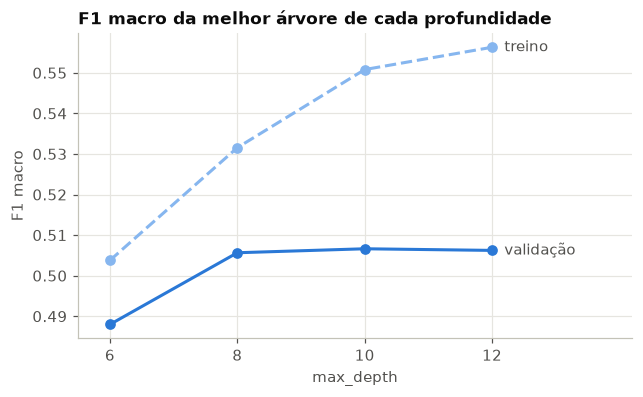

In [16]:
import matplotlib.pyplot as plt

# Cores: azul para a árvore, laranja para a random forest, cinzento para prever sempre "normal"
AZUL, AZUL_CLARO, LARANJA, CINZA = "#2a78d6", "#86b6ef", "#eb6834", "#a3a29c"
TEXTO, TEXTO_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TEXTO, "axes.titlelocation": "left",
})

# Melhor combinação de cada profundidade
fig, ax = plt.subplots(figsize=(6.5, 3.6))
prof = por_profundidade.sort_values("max_depth")
ax.plot(prof["max_depth"], prof["f1_treino"], color=AZUL_CLARO, lw=2, ls="--", marker="o", ms=6)
ax.plot(prof["max_depth"], prof["f1_validacao"], color=AZUL, lw=2, marker="o", ms=6)
ultimo = prof.iloc[-1]
ax.annotate("treino", (ultimo["max_depth"], ultimo["f1_treino"]), xytext=(8, 0), textcoords="offset points", va="center", color=TEXTO_2)
ax.annotate("validação", (ultimo["max_depth"], ultimo["f1_validacao"]), xytext=(8, 0), textcoords="offset points", va="center", color=TEXTO_2)
ax.set_xticks(prof["max_depth"])
ax.set_xlim(prof["max_depth"].min() - 0.5, prof["max_depth"].max() + 2.2)
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 macro")
ax.set_title("F1 macro da melhor árvore de cada profundidade")
plt.show()

In [17]:
# Efeito médio de cada hiperparâmetro no F1 de validação
for nome in GRELHA:
    print(resultados.groupby(nome)["f1_validacao"].mean().round(3).to_dict())

{'entropy': 0.484, 'gini': 0.49}
{'balanced': 0.479, 'raiz': 0.495}
{6: 0.479, 8: 0.488, 10: 0.493, 12: 0.488}
{10: 0.486, 20: 0.487, 40: 0.488, 80: 0.486}
{2: 0.486, 150: 0.487}


O peso das classes é o hiperparâmetro que mais conta. Os pesos raiz ficam em média 1,6 pontos acima de `balanced` e estão em todas as dez melhores combinações. A profundidade também conta, as árvores com 10 níveis ficam cerca de 1,4 pontos acima das de 6, e as de 8 e 12 ficam a meio. Gini e entropia dão quase o mesmo, tal como `min_samples_leaf` e `min_samples_split`. Nas melhores combinações a diferença entre treino e validação fica abaixo de 6 pontos.

In [18]:
MELHORES = resultados.iloc[0][list(GRELHA)].to_dict()
MELHORES["class_weight"] = PESOS[MELHORES["class_weight"]]
for nome in ["max_depth", "min_samples_leaf", "min_samples_split"]:
    MELHORES[nome] = int(MELHORES[nome])
print(MELHORES)

prev_melhor = validacao_cruzada(MELHORES)
pd.DataFrame({
    "Árvore inicial": metricas(y_treino, prev_todas),
    "Árvore otimizada": metricas(y_treino, prev_melhor),
}).T.round(3)

{'criterion': 'gini', 'class_weight': {'normal': 0.794, 'alto': 1.162, 'baixo': 1.219}, 'max_depth': 10, 'min_samples_leaf': 40, 'min_samples_split': 150}


,accuracy,f1_macro,recall_baixo,recall_normal,recall_alto
Árvore inicial,0.500,0.480,0.542,0.520,0.418
Árvore otimizada,0.543,0.507,0.461,0.631,0.427


A árvore escolhida usa Gini, os pesos raiz, `max_depth=10`, `min_samples_leaf=40` e `min_samples_split=150`. As dez melhores combinações ficam entre 0,503 e 0,507 de F1 na validação, com desvios entre folds de 0,005 a 0,013, por isso estão praticamente empatadas e ficamos com a primeira. Em relação à árvore inicial o F1 macro sobe de 0,48 para 0,51 e a accuracy de 0,50 para 0,54. Com pesos mais baixos nas classes `baixo` e `alto`, a árvore acerta mais vendas `normal`, 63% contra 52%, e menos vendas `baixo`, 46% contra 54%.

## Analisar o modelo final

A árvore final é treinada com os melhores hiperparâmetros em todo o conjunto de treino.

In [19]:
final = DecisionTreeClassifier(**MELHORES).fit(X_treino, y_treino)
print(f"Profundidade: {final.get_depth()} | folhas: {final.get_n_leaves()}\n")
print(final.export_text(max_depth=3))

Profundidade: 10 | folhas: 134

view <= 0.5
|   AreaCave <= 72.0
|   |   yr_built <= 1967.5
|   |   |   → normal  (n=5411; alto: 27%, baixo: 26%, normal: 47%)  [...]
|   |   yr_built > 1967.5
|   |   |   → normal  (n=8011; alto: 21%, baixo: 16%, normal: 63%)  [...]
|   AreaCave > 72.0
|   |   AreaCave <= 104.5
|   |   |   → baixo  (n=1529; alto: 11%, baixo: 39%, normal: 51%)  [...]
|   |   AreaCave > 104.5
|   |   |   → baixo  (n=659; alto: 8%, baixo: 60%, normal: 32%)  [...]
view > 0.5
|   waterfront = 0
|   |   AreaCave <= 66.4
|   |   |   → alto  (n=824; alto: 56%, baixo: 8%, normal: 37%)  [...]
|   |   AreaCave > 66.4
|   |   |   → alto  (n=718; alto: 42%, baixo: 21%, normal: 37%)  [...]
|   waterfront = 1
|   |   → alto  (n=138; alto: 93%, baixo: 1%, normal: 5%)


In [20]:
final.feature_importances().head(12).round(3)

AreaCave               0.183
AreaCasa               0.147
view                   0.146
yr_built               0.142
grade                  0.117
AreaTerrenoVizinhos    0.056
AreaCasaVizinhos       0.050
condition              0.046
AnoUltimaObra          0.044
AreaTerreno            0.022
waterfront             0.019
Meses                  0.013
dtype: float64

In [21]:
# Folhas com pelo menos 30 vendas onde a árvore prevê baixo ou alto, das mais puras para as menos puras
regras_finais = final.rules()
regras_finais[(regras_finais["classe"] != "normal") & (regras_finais["n"] >= 30)].sort_values("pureza", ascending=False).head(10)

,regra,classe,n,pureza,%alto,%baixo,%normal
28,view > 0.5 E waterfront = 1,alto,138,0.935,0.935,0.014,0.051
104,view > 0.5 E waterfront = 0 E AreaCave <= 66.4 E yr_built <= 1971.5 E grade > 7.5 E 783.2 < AreaTerrenoVizinhos <= 1253.4,alto,56,0.929,0.929,0.000,0.071
25,view <= 0.5 E AreaCave > 104.5 E AnoUltimaObra <= 2006.5 E condition <= 4.5 E AreaCasaVizinhos <= 285.7 E bedrooms <= 5.5 E AreaCasa > 256.9 E yr_built > 1957.5 E grade <= 8.5,baixo,144,0.868,0.007,0.868,0.125
86,view > 0.5 E waterfront = 0 E AreaCave > 66.4 E AreaCasaVizinhos > 188.1 E yr_built <= 1938.5,alto,71,0.817,0.817,0.042,0.141
66,view <= 0.5 E AreaCave > 104.5 E AnoUltimaObra <= 2006.5 E condition <= 4.5 E AreaCasaVizinhos <= 285.7 E bedrooms <= 5.5 E AreaCasa <= 256.9 E Meses > 4.5,baixo,94,0.734,0.064,0.734,0.202
97,view > 3.5 E waterfront = 0 E AreaCave > 66.4 E AreaCasaVizinhos > 188.1 E yr_built > 1938.5 E AreaCasa <= 410.2,alto,60,0.733,0.733,0.050,0.217
62,view <= 0.5 E 84.1 < AreaCave <= 104.5 E grade <= 7.5 E condition <= 4.5 E bathrooms <= 1.9 E AreaCasaVizinhos <= 171.4,baixo,99,0.727,0.030,0.727,0.242
72,view <= 0.5 E AreaCave <= 72.0 E yr_built > 2010.5 E grade > 8.5 E AreaTerrenoVizinhos > 136.4 E AreaCasa <= 286.6 E AreaTerreno <= 476.7,alto,91,0.725,0.725,0.011,0.264
100,view <= 0.5 E AreaCave <= 72.0 E yr_built > 2010.5 E grade > 7.5 E AreaTerrenoVizinhos <= 136.4,alto,58,0.724,0.724,0.017,0.259
116,view <= 0.5 E AreaCave <= 72.0 E yr_built > 1967.5 E grade <= 7.5 E AreaCasa <= 118.2 E AreaTerrenoVizinhos <= 356.2 E AnoUltimaObra <= 1999.5,baixo,43,0.721,0.023,0.721,0.256


In [22]:
# F1 macro pela qualidade da construção, com as previsões da validação cruzada da árvore otimizada
grupo_grade = pd.cut(treino["grade"], [0, 6, 7, 8, 13], labels=["até 6", "7", "8", "9 ou mais"])
pd.DataFrame({
    g: {"n": int((grupo_grade == g).sum()),
        **metricas(y_treino[grupo_grade == g], prev_melhor[grupo_grade == g])}
    for g in grupo_grade.cat.categories
}).T.round(3)

,n,accuracy,f1_macro,recall_baixo,recall_normal,recall_alto
até 6,1844.0,0.457,0.434,0.656,0.355,0.317
7,7194.0,0.541,0.482,0.444,0.655,0.335
8,4861.0,0.568,0.501,0.370,0.705,0.407
9 ou mais,3391.0,0.557,0.521,0.421,0.578,0.582


A árvore final usa mais a cave, a área da casa, a vista, o ano de construção e a qualidade da construção. As casas com vista e à beira de água têm 93% de vendas `alto`. As casas com vista mas longe da água, com cave até 66 m², construídas até 1971, `grade` acima de 7 e vizinhos com terrenos entre 783 e 1 253 m² também têm 93%. No lado oposto, a folha `baixo` mais pura, com 87%, junta casas sem vista, com mais de 105 m² de cave, sem obras desde 2006 e com mais de 257 m² de área, entre outras condições. Os quartos e as casas de banho praticamente não contam, porque já estão na regressão.

O F1 macro sobe com a qualidade da construção, de 0,43 nas casas com `grade` até 6 para 0,52 nas casas com 9 ou mais. Nas casas com `grade` até 6 a árvore encontra 66% das vendas `baixo` mas só 36% das `normal`.

## Random forest

Treinamos também uma random forest com o código em `libs/randomforest.py`, que usa a nossa árvore. Às variáveis da árvore juntamos as cinco variáveis novas do `01_EDA`. Testamos `max_features` e `min_samples_leaf` com 50 árvores, os pesos raiz e os mesmos folds.

In [23]:
from libs.randomforest import RandomForestClassifier

NOVAS = ["FracaoCave", "AreaVsVizinhos", "LoteVsVizinhos", "AnosSemObras", "AreaPorQuarto"]


def preparar_forest(treino, outro):
    """As variáveis da árvore mais as cinco variáveis novas."""
    X_treino, X_outro = preparar(treino, outro)
    return pd.concat([X_treino, treino[NOVAS]], axis=1), pd.concat([X_outro, outro[NOVAS]], axis=1)


def validacao_cruzada_forest(params):
    """Prever cada venda do treino com a forest treinada nos outros folds."""
    previsoes = np.empty(len(treino), dtype=object)
    for X_tr, X_val, idx_tr, idx_val in folds_forest:
        modelo = RandomForestClassifier(**params).fit(X_tr, y_treino[idx_tr])
        previsoes[idx_val] = modelo.predict(X_val)
    return previsoes


folds_forest = [(*preparar_forest(treino.iloc[idx_tr], treino.iloc[idx_val]), idx_tr, idx_val)
                for idx_tr, idx_val in cv.split(treino, y_treino)]

GRELHA_FOREST = {"max_features": ["sqrt", 0.5], "min_samples_leaf": [20, 40]}

resultados_forest = []
inicio = perf_counter()
for valores in product(*GRELHA_FOREST.values()):
    combinacao = dict(zip(GRELHA_FOREST, valores))
    params = {**combinacao, "n_estimators": 50, "class_weight": PESOS["raiz"],
              "random_state": SEMENTE, "n_jobs": -1}
    resultados_forest.append({**combinacao, **metricas(y_treino, validacao_cruzada_forest(params))})

print(f"{len(resultados_forest)} combinações em {perf_counter() - inicio:.0f} s")
resultados_forest = pd.DataFrame(resultados_forest).sort_values("f1_macro", ascending=False, ignore_index=True)
resultados_forest.round(3)

4 combinações em 82 s


,max_features,min_samples_leaf,accuracy,f1_macro,recall_baixo,recall_normal,recall_alto
0,sqrt,20,0.579,0.532,0.423,0.713,0.434
1,0.5,40,0.574,0.531,0.442,0.693,0.436
2,sqrt,40,0.575,0.529,0.424,0.702,0.438
3,0.5,20,0.574,0.529,0.428,0.703,0.431


As quatro combinações ficam entre 0,529 e 0,532. Escolhemos `max_features="sqrt"` e `min_samples_leaf=20` e passamos para 100 árvores.

In [24]:
PARAMS_FOREST = {**resultados_forest.iloc[0][list(GRELHA_FOREST)].to_dict(),
                 "n_estimators": 100, "class_weight": PESOS["raiz"], "random_state": SEMENTE, "n_jobs": -1}
PARAMS_FOREST["min_samples_leaf"] = int(PARAMS_FOREST["min_samples_leaf"])
print(PARAMS_FOREST)

# Validação cruzada da forest com 100 árvores, ao lado da árvore otimizada
prev_forest = validacao_cruzada_forest(PARAMS_FOREST)
pd.DataFrame({
    "Árvore otimizada": metricas(y_treino, prev_melhor),
    "Random forest": metricas(y_treino, prev_forest),
}).T.round(3)

{'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 100, 'class_weight': {'normal': 0.794, 'alto': 1.162, 'baixo': 1.219}, 'random_state': 42, 'n_jobs': -1}


,accuracy,f1_macro,recall_baixo,recall_normal,recall_alto
Árvore otimizada,0.543,0.507,0.461,0.631,0.427
Random forest,0.578,0.530,0.419,0.713,0.433


In [25]:
# Forest final, treinada em todo o conjunto de treino
X_treino_forest, X_teste_forest = preparar_forest(treino, teste)
forest = RandomForestClassifier(**PARAMS_FOREST).fit(X_treino_forest, y_treino)
forest.feature_importances().head(12).round(3)

AreaVsVizinhos         0.104
AreaPorQuarto          0.070
AreaCasa               0.070
AreaTerrenoVizinhos    0.064
view                   0.064
yr_built               0.063
AreaCasaVizinhos       0.062
grade                  0.060
AreaTerreno            0.060
AnoUltimaObra          0.059
AnosSemObras           0.059
Meses                  0.048
dtype: float64

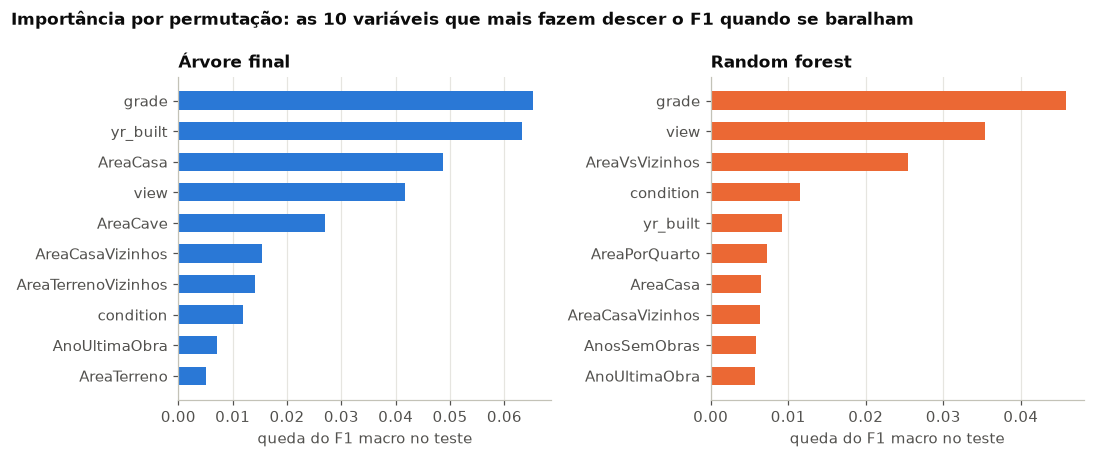

In [26]:
def importancia_permutacao(modelo, X, y, repeticoes=5):
    """Quanto desce o F1 macro quando se baralham os valores de cada variável."""
    rng = np.random.default_rng(SEMENTE)
    base = f1_score(y, modelo.predict(X), average="macro")
    quedas = {}
    for coluna in X.columns:
        valores = []
        for _ in range(repeticoes):
            X_baralhado = X.copy()
            X_baralhado[coluna] = rng.permutation(X_baralhado[coluna].to_numpy())
            valores.append(base - f1_score(y, modelo.predict(X_baralhado), average="macro"))
        quedas[coluna] = np.mean(valores)
    return pd.Series(quedas).sort_values(ascending=False)


imp_arvore = importancia_permutacao(final, X_teste, y_teste)
imp_forest = importancia_permutacao(forest, X_teste_forest, y_teste)

fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, imp, cor, titulo in [(eixos[0], imp_arvore, AZUL, "Árvore final"), (eixos[1], imp_forest, LARANJA, "Random forest")]:
    top = imp.head(10)[::-1]
    ax.barh(top.index, top.values, color=cor, height=0.6)
    ax.axvline(0, color="#c3c2b7", lw=1)
    ax.set_title(titulo)
    ax.set_xlabel("queda do F1 macro no teste")
    ax.grid(axis="y", visible=False)
fig.suptitle("Importância por permutação: as 10 variáveis que mais fazem descer o F1 quando se baralham",
             x=0.01, ha="left", fontsize=11, fontweight="bold", color=TEXTO)
fig.tight_layout()
plt.show()

Na validação cruzada a forest tem F1 macro de 0,53 e accuracy de 0,58, contra 0,51 e 0,54 da árvore.

As importâncias da forest dão a `Meses` 0,048, perto das variáveis de área, embora quase não conte na árvore, por isso medimos também quanto desce o F1 no teste quando se baralha cada variável. A qualidade da construção é a mais importante nos dois modelos. Na árvore seguem-se o ano de construção, a área e a vista, e na forest a vista, `AreaVsVizinhos` e o estado de conservação. `Meses` não aparece entre as dez primeiras.

## Avaliar no teste

In [27]:
prev_teste = final.predict(X_teste)
prev_teste_forest = forest.predict(X_teste_forest)
pd.DataFrame({
    "Sempre 'normal'": metricas(y_teste, np.full(len(y_teste), "normal")),
    "Árvore final": metricas(y_teste, prev_teste),
    "Random forest": metricas(y_teste, prev_teste_forest),
}).T.round(3)

,accuracy,f1_macro,recall_baixo,recall_normal,recall_alto
Sempre 'normal',0.529,0.231,0.000,1.000,0.000
Árvore final,0.536,0.501,0.489,0.618,0.405
Random forest,0.587,0.542,0.445,0.714,0.443


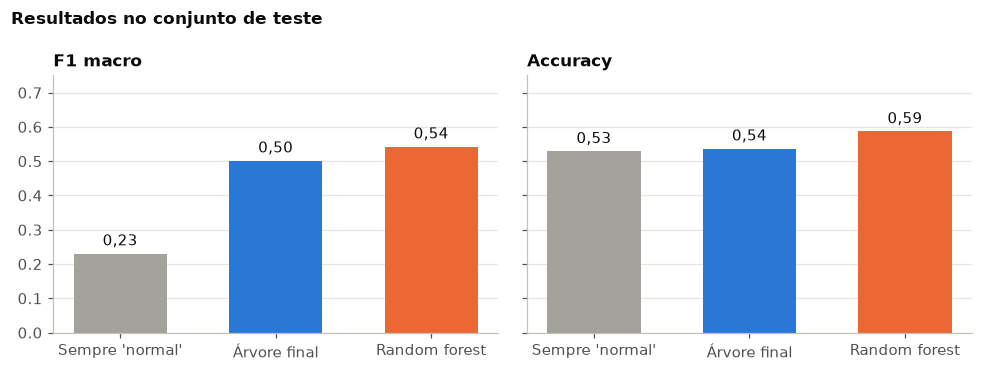

In [28]:
modelos = {"Sempre 'normal'": np.full(len(y_teste), "normal"), "Árvore final": prev_teste, "Random forest": prev_teste_forest}
cores = [CINZA, AZUL, LARANJA]

fig, eixos = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, metrica in zip(eixos, ["f1_macro", "accuracy"]):
    valores = [metricas(y_teste, p)[metrica] for p in modelos.values()]
    barras = ax.bar(list(modelos), valores, color=cores, width=0.6)
    ax.bar_label(barras, labels=[f"{v:.2f}".replace(".", ",") for v in valores], padding=3, color=TEXTO)
    ax.set_title("F1 macro" if metrica == "f1_macro" else "Accuracy")
    ax.set_ylim(0, 0.75)
    ax.grid(axis="x", visible=False)
fig.suptitle("Resultados no conjunto de teste", x=0.01, ha="left", fontsize=11, fontweight="bold", color=TEXTO)
fig.tight_layout()
plt.show()

In [29]:
pd.DataFrame(confusion_matrix(y_teste, prev_teste, labels=CLASSES),
             index=[f"real {c}" for c in CLASSES],
             columns=[f"previsto {c}" for c in CLASSES])

,previsto baixo,previsto normal,previsto alto
real baixo,474,387,109
real normal,471,1413,402
real alto,184,451,432


In [30]:
# Matriz de confusão da random forest
pd.DataFrame(confusion_matrix(y_teste, prev_teste_forest, labels=CLASSES),
             index=[f"real {c}" for c in CLASSES],
             columns=[f"previsto {c}" for c in CLASSES])

,previsto baixo,previsto normal,previsto alto
real baixo,432,450,88
real normal,317,1632,337
real alto,104,490,473


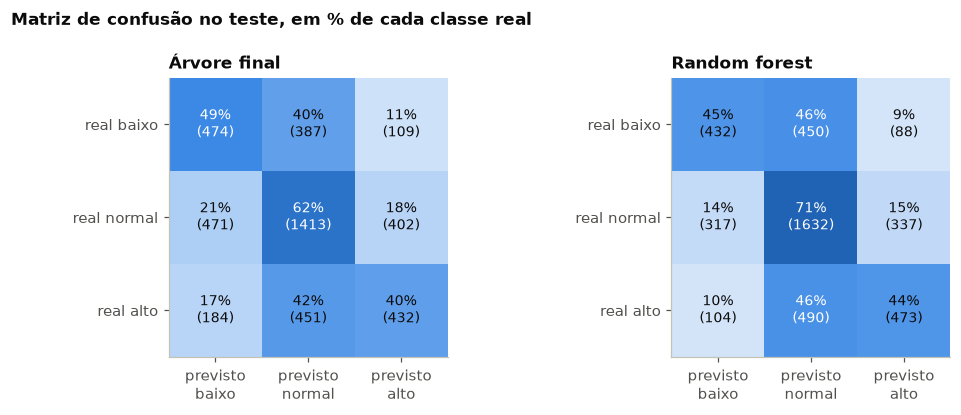

In [31]:
from matplotlib.colors import LinearSegmentedColormap

azuis = LinearSegmentedColormap.from_list("azuis", ["#f3f7fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])

fig, eixos = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, prev, titulo in [(eixos[0], prev_teste, "Árvore final"), (eixos[1], prev_teste_forest, "Random forest")]:
    matriz = confusion_matrix(y_teste, prev, labels=CLASSES)
    pct = matriz / matriz.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap=azuis, vmin=0, vmax=1)
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{pct[r, c]:.0%}\n({matriz[r, c]})", ha="center", va="center", fontsize=9,
                    color="white" if pct[r, c] > 0.45 else TEXTO)
    ax.set_xticks(range(3), [f"previsto\n{c}" for c in CLASSES])
    ax.set_yticks(range(3), [f"real {c}" for c in CLASSES])
    ax.grid(False)
    ax.set_title(titulo)
fig.suptitle("Matriz de confusão no teste, em % de cada classe real", x=0.01, ha="left", fontsize=11, fontweight="bold", color=TEXTO)
fig.tight_layout()
plt.show()

No teste a árvore tem F1 macro de 0,50, quase igual aos 0,51 da validação cruzada. Fica acima de prever sempre `normal`, que tem 0,23, e um pouco acima em accuracy, 0,54 contra 0,53. A árvore confunde pouco as classes extremas, só 11% das vendas `baixo` são previstas como `alto` e 17% das `alto` como `baixo`. O erro mais comum são vendas `normal` previstas como `baixo` ou `alto`, 44% dos erros.

A random forest tem F1 macro de 0,54 e accuracy de 0,59 no teste, 4 e 5 pontos acima da árvore. Encontra mais vendas `alto` e `normal`, 44% e 71% contra 41% e 62%, mas menos `baixo`, 45% contra 49%, e confunde menos as classes extremas, com 9% das `baixo` previstas como `alto` e 10% das `alto` como `baixo`. Das vendas que a árvore prevê como `baixo` e `alto`, 42% e 46% são mesmo dessa classe, e na forest são 51% e 53%, por isso cerca de metade das previsões `baixo` e `alto` estão erradas.

## Conclusão

O melhor modelo foi a random forest, com F1 macro de 0,54 e accuracy de 0,59 no teste. A árvore ficou em 0,50 e 0,54, e prever sempre `normal` em 0,23 e 0,53. A árvore fica abaixo da forest mas pode ser lida como regras. Nos dois modelos, as variáveis que mais afastam uma venda do preço esperado são a qualidade da construção, a vista, o ano de construção e a área da casa.